# Machine Learning -- Jour 2
## scikit-learn : predie a partir de donnees

**Master GI# -- Approche Probleme / Solution**

Objectifs:
- Comprendre la difference entre une regle ecrite a la main et un modele appris
- Maitriser le cycle train/test, fit, predict, evaluate
- Savoir lire une accuracy et une matrice de confusion avec un esprit critique
- Reconnaitre un cas de fuite de donnees (data leakage)

## 0. Mise en place
Avant de lancer la moindre cellule:
1. Installer scikit-learn si besoin : 'pip install scikit-learn'
2. Placez 'notes_etudiants.csv' (le meme fichier que le jour 1) dans le meme dossier que ce notebook

In [1]:
import os

if os.path.exists("/home/rwan-alex/Downloads"):
    print("Fichier trouve")
else:
    print("Fichier INTROUVABLE : verifiez son emplacement")

Fichier trouve


## 1. Le probleme
Un etudiant n'a pour l'instant que ses notes de maths et d'informatique (la note de physique n'est pas encore disponible). Peut-on predire des maintenant s'il va reussir (moyennee generale >= 10)?

In [2]:
import pandas as pd

df= pd.read_csv("notes_etudiants.csv")
df["note_physique"]= df["note_physique"].fillna(df["note_physique"].mean())
df["moyenne_generale"]= df[["note_maths","note_info","note_physique"]].mean(axis=1)
df["reussite"]=(df["moyenne_generale"] >= 10).astype(int)

print(df[["note_maths","note_info","note_physique","moyenne_generale","reussite"]].head())
print("\n Repartition reussite/echec :")
print(df["reussite"].value_counts())

   note_maths  note_info  note_physique  moyenne_generale  reussite
0       11.07      13.92      15.910000         13.633333         1
1       14.95      14.12       9.916058         12.995353         1
2        7.18      13.85       8.400000          9.810000         0
3       18.94      16.92      19.360000         18.406667         1
4       14.13       8.10      12.560000         11.596667         1

 Repartition reussite/echec :
reussite
1    3314
0    1686
Name: count, dtype: int64


## 2. Premiere tentative : une regle ecrite a la main

"Un etudiant reussit si sa note mathematiques est superieure ou egale a 10"

In [3]:
prediction_naive= (df["note_maths"]>= 10).astype(int)
accuracy_naive= (prediction_naive== df["reussite"]).mean()
print(prediction_naive)
print(f"Accuracy de la regle naive : {accuracy_naive:.3f}")

# Base de la composition : toujours predire la classe majoritaire
baseline = df["reussite"].value_counts(normalize=True).max()
print(f"Baseline (toujours predire la classe majoritaire) : {baseline:.3f}")


0       1
1       1
2       0
3       1
4       1
       ..
4995    1
4996    1
4997    1
4998    1
4999    1
Name: note_maths, Length: 5000, dtype: int64
Accuracy de la regle naive : 0.706
Baseline (toujours predire la classe majoritaire) : 0.663


** A retenir** : le seuil et la variable choisie sont arbitraires, on n'utilise pas toute l'information disponible, et on ne peut pas savoir si la regle est bonne sans la comparer a un vrai modele.

-> Laissons un algorithme apprendre la meilleure combinaison a partir des exemples.

## 3. scikit-learn : le cycle de base

Separer les donnees -> entrainer -> predire -> evaluer.

Accuracy : 0.798
Matrice de confusion :
 [[207 125]
 [ 77 591]]


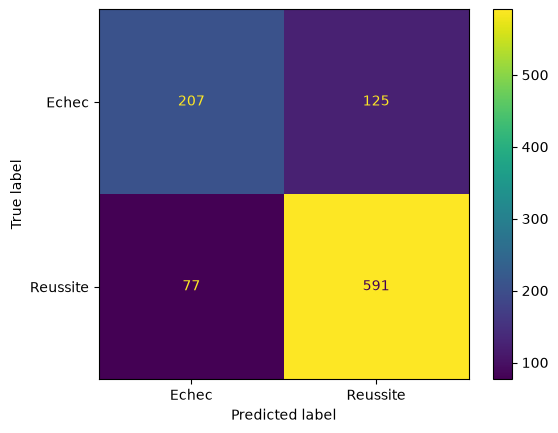

In [13]:
# Modele avec maths, info

import pandas as pd
from sklearn.model_selection import train_test_split # Pour diviser les donnees d'entrainement et les donnees de test
from sklearn.linear_model import LogisticRegression # Pour choisir le modele de regression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

df= pd.read_csv("notes_etudiants.csv")

df= pd.read_csv("notes_etudiants.csv")
df["note_physique"]= df["note_physique"].fillna(df["note_physique"].mean())
df["moyenne_generale"]= df[["note_maths","note_info","note_physique"]].mean(axis=1)
df["reussite"]=(df["moyenne_generale"] >= 10).astype(int)

X= df[["note_maths", "note_info"]] # variables explicatives (features)
y= df["reussite"] # variables a predire (target)

X_train, X_test, y_train, y_test = train_test_split( #
    X, y, test_size=0.2, random_state=42
)

modele= LogisticRegression()
modele.fit(X_train, y_train)

y_pred= modele.predict(X_test)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Matrice de confusion :\n", confusion_matrix(y_test, y_pred))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred,display_labels=['Echec', 'Reussite'])


In [14]:
# TP A FAIRE, modele avec maths, info et physique

import pandas as pd
from sklearn.model_selection import train_test_split as tts # Pour diviser les donnees d'entrainement et les don
from sklearn.linear_model import LogisticRegression # Modele de classification
from sklearn.metrics import accuracy_score, confusion_matrix #

df= pd.read_csv("notes_etudiants.csv")

df= pd.read_csv("notes_etudiants.csv")
df["note_physique"]= df["note_physique"].fillna(df["note_physique"].mean())
df["moyenne_generale"]= df[["note_maths","note_info","note_physique"]].mean(axis=1)
df["reussite"]=(df["moyenne_generale"] >= 10).astype(int)

X= df[["note_maths", "note_info", "note_physique"]] # variables explicatives (features)
y= df["reussite"] # variables a predire (target)

X_train, X_test, y_train, y_test = tts( #
    X, y, test_size=0.3, random_state=42
)

modele= LogisticRegression()
modele.fit(X_train, y_train)

y_pred= modele.predict(X_test)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Matrice de confusion :\n", confusion_matrix(y_test, y_pred))

Accuracy : 0.9993333333333333
Matrice de confusion :
 [[502   1]
 [  0 997]]


In [15]:
# Modele avec juste la note de mathematiques

import pandas as pd
from sklearn.model_selection import train_test_split  # Pour diviser les donnees d'entrainement et les don
from sklearn.linear_model import LogisticRegression # Modele de classification
from sklearn.metrics import accuracy_score, confusion_matrix #

df= pd.read_csv("notes_etudiants.csv")

df= pd.read_csv("notes_etudiants.csv")
df["note_physique"]= df["note_physique"].fillna(df["note_physique"].mean())
df["moyenne_generale"]= df[["note_maths","note_info","note_physique"]].mean(axis=1)
df["reussite"]=(df["moyenne_generale"] >= 10).astype(int)

X= df[["note_maths"]] # variables explicatives (features)
y= df["reussite"] # variables a predire (target)

X_train, X_test, y_train, y_test = train_test_split( #
    X, y, test_size=0.2, random_state=42
)

modele= LogisticRegression()
modele.fit(X_train, y_train)

y_pred= modele.predict(X_test)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Matrice de confusion :\n", confusion_matrix(y_test, y_pred))

Accuracy : 0.718
Matrice de confusion :
 [[141 191]
 [ 91 577]]
